# Credit Card Fraud Detection: Experiment Notebook
**Mohan Mekala · IEEE paper: Credit Card Fraud Detection Using Machine Learning with Imbalance-Aware Evaluation and Explainability**

This notebook runs the full experiment described in the paper on the **FDB `sparknov` task** and produces every value marked **[run]**:

| Output | Goes into the paper |
|---|---|
| Data profile | Table II, Sec. III-D |
| CV + validation results | Table IV |
| Test results | Table V |
| Default vs. tuned threshold | Table VI |
| Bootstrap 95% intervals | Sec. VIII-E |
| PR curves / confusion matrix / SHAP | Figs. 11, 12, 13 |
| Ablation E1–E5 | Appendix O (Table XIII) |

**How to use:** run the cells from top to bottom (*Runtime → Run all* after Step 2). At the end, a zip of all results downloads automatically.

> Report the numbers exactly as they come out. If you change `SAMPLE_FRAC` or `FAST`, state this in Section VI-B of the paper.

## Step 1 — Install packages
Takes 1–2 minutes. Colab already has pandas, scikit-learn and matplotlib.

In [9]:
!pip install -q imbalanced-learn xgboost shap kaggle
!git clone -q https://github.com/amazon-science/fraud-dataset-benchmark.git
!pip install -q ./fraud-dataset-benchmark

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Step 2 — Kaggle API token
FDB downloads `sparknov` from Kaggle, so you need a free Kaggle account:
1. Go to **kaggle.com → Settings → API → Create New Token**. This downloads `kaggle.json`.
2. Run the cell below and upload that file when prompted.

In [10]:
import os, shutil
from google.colab import files
uploaded = files.upload()                      # choose kaggle.json
os.makedirs("/root/.kaggle", exist_ok=True)
shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)
print("Kaggle token installed")

Saving kaggle.json to kaggle.json
Kaggle token installed


## Step 3 — Settings
* `SAMPLE_FRAC`: share of the training partition used for fitting (stratified). Use **1.0** for the full experiment. That can take several hours on free Colab, so **0.3** is the default here.
* `FAST`: smaller hyperparameter grid. Set it to `False` to use the full grid in Table III.
* `DATA_SOURCE`: `"fdb"` uses the FDB loader. `"csv"` uses your own `train.csv` / `test.csv` uploaded to the Colab file panel.

In [11]:
SEED          = 42
SAMPLE_FRAC   = 0.3      # 1.0 = full training partition
FAST          = True     # False = full grid of Table III
RUN_ABLATION  = True     # Table XIII experiments E1-E5
DATA_SOURCE   = "fdb"    # "fdb" or "csv"
TRAIN_CSV, TEST_CSV = "train.csv", "test.csv"
OUT = "results"

In [12]:
import os, json, time, platform, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipe
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, average_precision_score,
                             roc_auc_score, precision_recall_curve, confusion_matrix)
warnings.filterwarnings("ignore")
try:
    from imblearn.pipeline import Pipeline
    from imblearn.over_sampling import SMOTE
    HAVE_IMB = True
except ImportError:
    from sklearn.pipeline import Pipeline; HAVE_IMB = False
try:
    from xgboost import XGBClassifier; HAVE_XGB = True
except ImportError:
    HAVE_XGB = False
try:
    import shap; HAVE_SHAP = True
except ImportError:
    HAVE_SHAP = False

FIG = f"{OUT}/figures"; ART = "artifacts"
for d in (OUT, FIG, ART): os.makedirs(d, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.size": 8})
LOG = []
def log(m): print(m); LOG.append(str(m))
T0 = time.time()
log(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | imblearn {HAVE_IMB} | xgboost {HAVE_XGB} | shap {HAVE_SHAP}")
log(f"Settings: SEED={SEED} SAMPLE_FRAC={SAMPLE_FRAC} FAST={FAST} ABLATION={RUN_ABLATION}")

Python 3.13.16 | scikit-learn 1.6.1 | imblearn True | xgboost True | shap True
Settings: SEED=42 SAMPLE_FRAC=0.3 FAST=True ABLATION=True


## Step 4 — Load the data
FDB returns its official training and test partitions. The first download takes a few minutes.

In [13]:
!pip install -q faker
if DATA_SOURCE == "fdb":
    from fdb.datasets import FraudDatasetBenchmark
    obj = FraudDatasetBenchmark(key="sparknov", load_pre_downloaded=False, delete_downloaded=True)
    train_raw, test_raw = obj.train.copy(), obj.test.copy()
    LABELS = ["EVENT_LABEL", "is_fraud", "label", "Class"]
    if not any(c in test_raw.columns for c in LABELS) and hasattr(obj, "test_labels"):
        # Check if EVENT_ID is a column; otherwise use index or left_index/right_index
        left_on = "EVENT_ID" if "EVENT_ID" in test_raw.columns else None
        right_on = "EVENT_ID" if "EVENT_ID" in obj.test_labels.columns else None

        if left_on and right_on:
            test_raw = test_raw.merge(obj.test_labels, on="EVENT_ID", how="left")
        else:
            test_raw = test_raw.merge(obj.test_labels, left_index=True, right_index=True, how="left")
    log("Loaded FDB task 'sparknov'")
else:
    train_raw, test_raw = pd.read_csv(TRAIN_CSV), pd.read_csv(TEST_CSV)
    log(f"Loaded {TRAIN_CSV} and {TEST_CSV}")
log(f"Train shape {train_raw.shape} | Test shape {test_raw.shape}")
print(list(train_raw.columns))
train_raw.head()

Data download location /content/tmp
Dataset URL: https://www.kaggle.com/datasets/kartik2112/fraud-detection
Loaded FDB task 'sparknov'
Train shape (1296675, 23) | Test shape (20000, 22)
['cc_num', 'ENTITY_ID', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'EVENT_ID', 'merch_lat', 'merch_long', 'EVENT_LABEL', 'EVENT_TIMESTAMP', 'LABEL_TIMESTAMP', 'ENTITY_TYPE']


,cc_num,ENTITY_ID,category,amt,first,last,gender,street,city,state,...,city_pop,job,dob,EVENT_ID,merch_lat,merch_long,EVENT_LABEL,EVENT_TIMESTAMP,LABEL_TIMESTAMP,ENTITY_TYPE
0,2703186189652095,fraud_rippin_kub_and_mann,misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,...,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,36.011293,-82.048315,0,2020-09-01T00:00:18Z,2026-10-24T01:05:59Z,user
1,630423337322,fraud_heller_gutmann_and_zieme,grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,...,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,49.159047,-118.186462,0,2020-09-01T00:00:44Z,2026-10-24T01:05:59Z,user
2,38859492057661,fraud_lind_buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,...,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,43.150704,-112.154481,0,2020-09-01T00:00:51Z,2026-10-24T01:05:59Z,user
3,3534093764340240,fraud_kutch_hermiston_and_farrell,gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,...,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,47.034331,-112.561071,0,2020-09-01T00:01:16Z,2026-10-24T01:05:59Z,user
4,375534208663984,fraud_keeling_crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,...,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,38.674999,-78.632459,0,2020-09-01T00:03:06Z,2026-10-24T01:05:59Z,user


## Step 5 — Identify label, time and feature columns
Identifier and free-text columns are excluded (paper, Sec. IV-B). **Check the printed lists.** They are reported in the paper.

In [15]:
LABEL_CANDIDATES = ["EVENT_LABEL", "is_fraud", "label", "Class", "fraud"]
TIME_CANDIDATES  = ["EVENT_TIMESTAMP", "trans_date_trans_time", "unix_time", "timestamp"]
DROP_ALWAYS = {"EVENT_ID", "ENTITY_ID", "ENTITY_TYPE", "LABEL_TIMESTAMP", "EVENT_TYPE", "trans_num", "cc_num",
               "first", "last", "street", "Unnamed: 0", "index"}
MAX_CATEGORIES = 60
find = lambda df, c: next((x for x in c if x in df.columns), None)
Y_COL, T_COL = find(train_raw, LABEL_CANDIDATES), find(train_raw, TIME_CANDIDATES)
assert Y_COL is not None, "Label column not found - check the printed column list"
for df in (train_raw, test_raw):
    df[Y_COL] = df[Y_COL].astype(int)
    assert set(df[Y_COL].unique()) <= {0, 1}, "Unexpected label values"
    if T_COL is not None:
        df["_t"] = (pd.to_datetime(df[T_COL], errors="coerce") if df[T_COL].dtype == object
                    else pd.to_datetime(df[T_COL], unit="s", errors="coerce"))
feats = [c for c in train_raw.columns if c not in DROP_ALWAYS | {Y_COL, T_COL, "_t"}]
NUM = [c for c in feats if pd.api.types.is_numeric_dtype(train_raw[c])]
CAT = [c for c in feats if c not in NUM and train_raw[c].nunique() <= MAX_CATEGORIES]
dropped = sorted(set(feats) - set(NUM) - set(CAT)) + sorted(DROP_ALWAYS & set(train_raw.columns))
log(f"Label: {Y_COL} | Time: {T_COL}")
log(f"Numeric ({len(NUM)}): {NUM}")
log(f"Categorical ({len(CAT)}): {CAT}")
log(f"Excluded (ID / free text / high cardinality): {dropped}")

Label: EVENT_LABEL | Time: EVENT_TIMESTAMP
Numeric (7): ['amt', 'zip', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long']
Categorical (3): ['category', 'gender', 'state']
Excluded (ID / free text / high cardinality): ['city', 'dob', 'job', 'ENTITY_ID', 'ENTITY_TYPE', 'EVENT_ID', 'LABEL_TIMESTAMP', 'cc_num', 'first', 'last', 'street']


## Step 6 — Partitions and data profile (Table II, Fig. 5)
The FDB test set is used exactly as released. Validation is the **latest 15%** of the FDB training data by time.

In [16]:
n_dup = int(train_raw.duplicated(subset=[c for c in train_raw.columns if c != "_t"]).sum())
log(f"Exact duplicate rows in FDB training data (removed before splitting): {n_dup}")
tr = train_raw.drop_duplicates(subset=[c for c in train_raw.columns if c != "_t"])
if T_COL is not None:
    tr = tr.sort_values("_t"); cut = int(len(tr) * 0.85)
    fit, va = tr.iloc[:cut].copy(), tr.iloc[cut:].copy()
    log(f"Chronological split: fit data up to {fit['_t'].max()}, validation from {va['_t'].min()}")
else:
    fit, va = train_test_split(tr, test_size=0.15, stratify=tr[Y_COL], random_state=SEED)
    log("No timestamp found: stratified 85/15 split")
te = test_raw
fit_full_rows = len(fit)
if SAMPLE_FRAC < 1.0:
    fit, _ = train_test_split(fit, train_size=SAMPLE_FRAC, stratify=fit[Y_COL], random_state=SEED)
    log(f"Fit data subsampled to {SAMPLE_FRAC:.0%} (stratified): {len(fit):,} of {fit_full_rows:,} rows")

def profile(name, df):
    X = df[NUM + CAT]
    return {"partition": name, "rows": len(df), "fraud_cases": int(df[Y_COL].sum()),
            "fraud_rate_%": round(100 * df[Y_COL].mean(), 3), "missing_values": int(X.isna().sum().sum()),
            "numeric_features": len(NUM), "categorical_features": len(CAT)}
table_II = pd.DataFrame([profile("train (fit)", fit), profile("validation", va), profile("test", te)])
table_II.to_csv(f"{OUT}/table_II_data_profile.csv", index=False)
table_II

Exact duplicate rows in FDB training data (removed before splitting): 0
Chronological split: fit data up to 2021-12-03 17:53:52+00:00, validation from 2021-12-03 17:54:44+00:00
Fit data subsampled to 30% (stratified): 330,651 of 1,102,173 rows


,partition,rows,fraud_cases,fraud_rate_%,missing_values,numeric_features,categorical_features
0,train (fit),330651,1912,0.578,0,7,3
1,validation,194502,1133,0.583,0,7,3
2,test,20000,91,0.455,0,7,3


## Step 7 — Exploratory figures (optional for Sec. III-D)

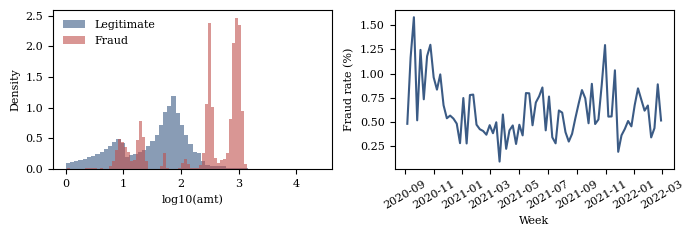

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(7, 2.4))
amt = next((c for c in ["amt", "amount", "Amount", "TransactionAmt"] if c in fit.columns), NUM[0])
for lab, c in [(0, "#3B5B85"), (1, "#C0504D")]:
    v = fit.loc[fit[Y_COL] == lab, amt].clip(lower=0.01)
    axs[0].hist(np.log10(v), bins=60, density=True, alpha=0.6, color=c, label=["Legitimate", "Fraud"][lab])
axs[0].set_xlabel(f"log10({amt})"); axs[0].set_ylabel("Density"); axs[0].legend(frameon=False)
if T_COL is not None:
    wk = pd.concat([fit, va]).set_index("_t")[Y_COL].resample("W").mean() * 100
    axs[1].plot(wk.index, wk.values, color="#3B5B85"); axs[1].set_ylabel("Fraud rate (%)"); axs[1].set_xlabel("Week")
    axs[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{FIG}/eda_amount_and_weekly_rate.png", dpi=300); plt.show()

## Step 8 — Hyperparameter search with 5-fold stratified CV (Table IV)
Scoring is average precision (PR-AUC). This is the slowest step.

In [18]:
X, Xv, Xt = fit[NUM + CAT], va[NUM + CAT], te[NUM + CAT]
Y, Yv, Yt = fit[Y_COL].values, va[Y_COL].values, te[Y_COL].values
RATIO = float((Y == 0).sum() / max((Y == 1).sum(), 1))

def preprocessor(scale):
    num_steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("num", SkPipe(num_steps), NUM),
        ("cat", SkPipe([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                        ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CAT)])
def make_pipe(clf, scale, smote=False):
    steps = [("prep", preprocessor(scale))]
    if smote: steps.append(("smote", SMOTE(random_state=SEED)))
    return Pipeline(steps + [("clf", clf)])

GRIDS = {
  "Logistic Regression": (LogisticRegression(max_iter=2000, solver="liblinear", random_state=SEED), True,
      {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
  "Random Forest": (RandomForestClassifier(n_jobs=-1, random_state=SEED), False,
      {"clf__n_estimators": [200, 500], "clf__max_depth": [None, 10, 20], "clf__min_samples_leaf": [1, 5],
       "clf__class_weight": ["balanced", "balanced_subsample"]})}
if HAVE_XGB:
    GRIDS["XGBoost"] = (XGBClassifier(eval_metric="aucpr", tree_method="hist", n_jobs=-1, random_state=SEED), False,
      {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [3, 5, 7], "clf__n_estimators": [200, 500],
       "clf__scale_pos_weight": [1, RATIO]})
if FAST:
    GRIDS["Logistic Regression"][2].update({"clf__C": [0.1, 1]})
    GRIDS["Random Forest"][2].update({"clf__n_estimators": [200], "clf__max_depth": [None, 20], "clf__min_samples_leaf": [1]})
    if HAVE_XGB: GRIDS["XGBoost"][2].update({"clf__n_estimators": [300], "clf__max_depth": [5, 7]})

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
fitted, rows, cv_all = {}, [], []
maj = make_pipe(DummyClassifier(strategy="most_frequent"), False).fit(X, Y); fitted["Majority reference"] = maj
rows.append({"model": "Majority reference", "best_params": "none", "cv_pr_auc_mean": np.nan, "cv_pr_auc_sd": np.nan,
             "val_pr_auc": average_precision_score(Yv, maj.predict_proba(Xv)[:, 1])})
for name, (clf, scale, grid) in GRIDS.items():
    t = time.time(); n = int(np.prod([len(v) for v in grid.values()]))
    log(f"Grid search {name}: {n} settings x 5 folds ...")
    gs = GridSearchCV(make_pipe(clf, scale), grid, scoring="average_precision", cv=cv, n_jobs=1).fit(X, Y)
    r = pd.DataFrame(gs.cv_results_); r["model"] = name; cv_all.append(r); i = gs.best_index_
    fitted[name] = gs.best_estimator_
    rows.append({"model": name, "best_params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                 "cv_pr_auc_mean": r.loc[i, "mean_test_score"], "cv_pr_auc_sd": r.loc[i, "std_test_score"],
                 "val_pr_auc": average_precision_score(Yv, gs.best_estimator_.predict_proba(Xv)[:, 1])})
    log(f"  done in {(time.time()-t)/60:.1f} min | best {rows[-1]['best_params']}")
table_IV = pd.DataFrame(rows); table_IV.to_csv(f"{OUT}/table_IV_cv_validation.csv", index=False)
pd.concat(cv_all).to_csv(f"{OUT}/cv_results.csv", index=False)
LEARNERS = [m for m in fitted if m != "Majority reference"]
SEL = table_IV[table_IV.model.isin(LEARNERS)].sort_values("val_pr_auc", ascending=False).model.iloc[0]
log(f"SELECTED MODEL (highest validation PR-AUC; rule fixed before testing): {SEL}")
table_IV.round(4)

Grid search Logistic Regression: 4 settings x 5 folds ...
  done in 1.8 min | best {'C': 0.1, 'class_weight': None}
Grid search Random Forest: 4 settings x 5 folds ...
  done in 91.8 min | best {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Grid search XGBoost: 8 settings x 5 folds ...
  done in 9.4 min | best {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'scale_pos_weight': 1}
SELECTED MODEL (highest validation PR-AUC; rule fixed before testing): XGBoost


,model,best_params,cv_pr_auc_mean,cv_pr_auc_sd,val_pr_auc
0,Majority reference,none,NaN,NaN,0.0058
1,Logistic Regression,"{'C': 0.1, 'class_weight': None}",0.2050,0.0125,0.1998
2,Random Forest,"{'class_weight': 'balanced', 'max_depth': None...",0.7323,0.0087,0.6870
3,XGBoost,"{'learning_rate': 0.05, 'max_depth': 7, 'n_est...",0.7555,0.0164,0.7029


## Step 9 — Thresholds from validation, then the test set once (Tables V and VI)

In [19]:
def thr_f1(y, s):
    p, r, t = precision_recall_curve(y, s)
    f = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None); return float(t[int(np.nanargmax(f))])
def thr_recall(y, s, target=0.80):
    p, r, t = precision_recall_curve(y, s); ok = np.where(r[:-1] >= target)[0]
    return float(t[ok[np.argmax(p[:-1][ok])]]) if len(ok) else float(t[0])
def metrics(y, s, thr):
    yp = (s >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
    return {"precision": precision_score(y, yp, zero_division=0), "recall": recall_score(y, yp), "f1": f1_score(y, yp),
            "pr_auc": average_precision_score(y, s), "roc_auc": roc_auc_score(y, s), "accuracy": accuracy_score(y, yp),
            "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn), "threshold": thr}

THR = {"Majority reference": 0.5}; THR80 = {}
for m in LEARNERS:
    sv = fitted[m].predict_proba(Xv)[:, 1]; THR[m] = thr_f1(Yv, sv); THR80[m] = thr_recall(Yv, sv)
SCORES = {m: fitted[m].predict_proba(Xt)[:, 1] for m in fitted}          # test set: used once
table_V = pd.DataFrame([{"model": m, **metrics(Yt, SCORES[m], THR[m])} for m in fitted])
table_V.to_csv(f"{OUT}/table_V_test.csv", index=False)
rows = []
for m in LEARNERS:
    for lab, th in [("default 0.5", 0.5), ("validation F1-optimal", THR[m]), ("validation recall>=0.80", THR80[m])]:
        rows.append({"model": m, "setting": lab, **metrics(Yt, SCORES[m], th)})
table_VI = pd.DataFrame(rows); table_VI.to_csv(f"{OUT}/table_VI_thresholds.csv", index=False)
pd.DataFrame({"y_true": Yt, **{f"score_{m}": s for m, s in SCORES.items()}}).to_csv(f"{OUT}/test_predictions.csv", index=False)
print("TABLE V"); display(table_V.round(4)); print("TABLE VI"); display(table_VI.round(4))

TABLE V


,model,precision,recall,f1,pr_auc,roc_auc,accuracy,TP,FP,FN,TN,threshold
0,Majority reference,0.0000,0.0000,0.0000,0.0046,0.5000,0.9954,0,0,91,19909,0.5000
1,Logistic Regression,0.2584,0.5055,0.3420,0.2084,0.8147,0.9912,46,132,45,19777,0.0261
2,Random Forest,0.7326,0.6923,0.7119,0.6965,0.9549,0.9974,63,23,28,19886,0.2950
3,XGBoost,0.5583,0.7363,0.6351,0.6787,0.9945,0.9962,67,53,24,19856,0.1960


TABLE VI


,model,setting,precision,recall,f1,pr_auc,roc_auc,accuracy,TP,FP,FN,TN,threshold
0,Logistic Regression,default 0.5,0.0000,0.0000,0.0000,0.2084,0.8147,0.9948,0,13,91,19896,0.5000
1,Logistic Regression,validation F1-optimal,0.2584,0.5055,0.3420,0.2084,0.8147,0.9912,46,132,45,19777,0.0261
2,Logistic Regression,validation recall>=0.80,0.0095,0.7912,0.0188,0.2084,0.8147,0.6242,72,7498,19,12411,0.0038
3,Random Forest,default 0.5,0.8571,0.4615,0.6000,0.6965,0.9549,0.9972,42,7,49,19902,0.5000
4,Random Forest,validation F1-optimal,0.7326,0.6923,0.7119,0.6965,0.9549,0.9974,63,23,28,19886,0.2950
5,Random Forest,validation recall>=0.80,0.3807,0.8242,0.5208,0.6965,0.9549,0.9931,75,122,16,19787,0.0750
6,XGBoost,default 0.5,0.7000,0.4615,0.5563,0.6787,0.9945,0.9966,42,18,49,19891,0.5000
7,XGBoost,validation F1-optimal,0.5583,0.7363,0.6351,0.6787,0.9945,0.9962,67,53,24,19856,0.1960
8,XGBoost,validation recall>=0.80,0.4424,0.8022,0.5703,0.6787,0.9945,0.9945,73,92,18,19817,0.0801


## Step 10 — Bootstrap 95% intervals (Sec. VIII-E)

In [20]:
import sys
required_vars = ["np", "pd", "SEED", "LEARNERS", "Yt", "SCORES", "THR", "SEL", "OUT", "average_precision_score", "f1_score"]
missing_vars = [v for v in required_vars if v not in globals() and (v != "np" or "np" not in sys.modules) and (v != "pd" or "pd" not in sys.modules)]

if missing_vars:
    print(f"Warning: Preceding setup/model cells are not executed. Missing: {missing_vars}. Please run all cells from Step 3 to Step 9 first.")
else:
    rng = np.random.default_rng(SEED); out = []
    for m in LEARNERS:
        ap, f1, d = [], [], []
        for _ in range(1000):
            i = rng.integers(0, len(Yt), len(Yt))
            if Yt[i].sum() == 0: continue
            ap.append(average_precision_score(Yt[i], SCORES[m][i])); f1.append(f1_score(Yt[i], (SCORES[m][i] >= THR[m]).astype(int)))
            if m != SEL: d.append(ap[-1] - average_precision_score(Yt[i], SCORES[SEL][i]))
        row = {"model": m, "PR-AUC 95% CI": f"[{np.percentile(ap,2.5):.4f}, {np.percentile(ap,97.5):.4f}]",
               "F1 95% CI": f"[{np.percentile(f1,2.5):.4f}, {np.percentile(f1,97.5):.4f}]"}
        if d: row[f"PR-AUC minus {SEL} 95% CI"] = f"[{np.percentile(d,2.5):.4f}, {np.percentile(d,97.5):.4f}]"
        out.append(row)
    boot = pd.DataFrame(out); boot.to_csv(f"{OUT}/bootstrap_ci.csv", index=False); boot

## Step 11 — Figures 11 and 12

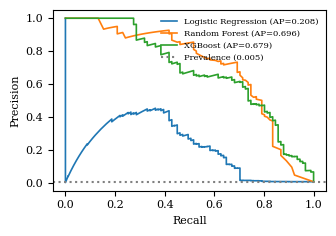

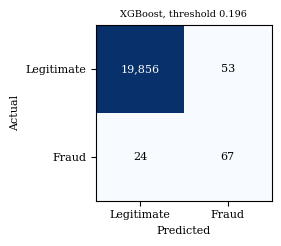

In [21]:
import sys
required_vars = ["plt", "LEARNERS", "Yt", "SCORES", "SEL", "THR", "FIG"]
missing_vars = [v for v in required_vars if v not in globals() and (v != "plt" or "plt" not in sys.modules)]

if missing_vars:
    print(f"Warning: Preceding setup/model cells are not executed. Missing: {missing_vars}. Please run all cells from Step 3 to Step 10 first to load libraries and train the models.")
else:
    fig, ax = plt.subplots(figsize=(3.4, 2.4))
    for m in LEARNERS:
        p, r, _ = precision_recall_curve(Yt, SCORES[m])
        ax.plot(r, p, lw=1.2, label=f"{m} (AP={average_precision_score(Yt, SCORES[m]):.3f})")
    ax.axhline(Yt.mean(), ls=":", color="gray", label=f"Prevalence ({Yt.mean():.3f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(fontsize=6, frameon=False)
    plt.tight_layout(); plt.savefig(f"{FIG}/fig11_pr_curves.png", dpi=300); plt.show()

    cm = confusion_matrix(Yt, (SCORES[SEL] >= THR[SEL]).astype(int))
    fig, ax = plt.subplots(figsize=(3.0, 2.5)); ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Legitimate", "Fraud"]); ax.set_yticks([0, 1], ["Legitimate", "Fraud"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{SEL}, threshold {THR[SEL]:.3f}", fontsize=7)
    plt.tight_layout(); plt.savefig(f"{FIG}/fig12_confusion_matrix.png", dpi=300); plt.show()

## Step 12 — SHAP explanation of the selected model (Fig. 13)

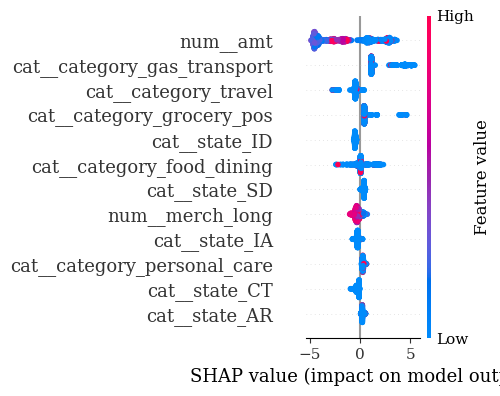

,feature,mean_abs_shap
0,num__amt,2.916261
9,cat__category_gas_transport,2.304187
20,cat__category_travel,0.526852
11,cat__category_grocery_pos,0.524902
36,cat__state_ID,0.499072
8,cat__category_food_dining,0.387699
64,cat__state_SD,0.339734
6,num__merch_long,0.311285
35,cat__state_IA,0.278564
17,cat__category_personal_care,0.275003


In [22]:
try:
    # Safe check if variables from preceding steps are initialized
    required_vars = ["HAVE_SHAP", "fitted", "SEL", "SEED", "Xt", "Yt", "FIG", "OUT"]
    missing = [var for var in required_vars if var not in globals()]
    if missing:
        print(f"Warning: Preceding setup/model cells are not executed. Missing: {missing}. Please run all cells from Step 3 to Step 11 first.")
    else:
        assert HAVE_SHAP, "shap not installed"
        best = fitted[SEL]; prep, clf = best.named_steps["prep"], best.named_steps["clf"]
        idx = np.random.default_rng(SEED).choice(len(Xt), min(1000, len(Xt)), replace=False)
        Xs = prep.transform(Xt.iloc[idx]); Xs = Xs.toarray() if hasattr(Xs, "toarray") else Xs
        names = list(prep.get_feature_names_out())
        expl = shap.LinearExplainer(clf, Xs) if SEL == "Logistic Regression" else shap.TreeExplainer(clf)
        sv = expl.shap_values(Xs); sv = sv[1] if isinstance(sv, list) else sv
        if np.ndim(sv) == 3: sv = sv[:, :, 1]
        shap.summary_plot(sv, Xs, feature_names=names, max_display=12, show=False, plot_size=(5, 4))
        plt.tight_layout(); plt.savefig(f"{FIG}/fig13_shap_summary.png", dpi=300); plt.show()
        imp = pd.DataFrame({"feature": names, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False)
        imp.to_csv(f"{OUT}/shap_importance.csv", index=False); display(imp.head(12))
except Exception as e:
    if "log" in globals():
        log(f"SHAP step skipped: {e}")
    else:
        print(f"SHAP step skipped: {e}")

## Step 13 — Ablation experiments E1–E5 (Table XIII, answers RQ2)

In [24]:
if 'RUN_ABLATION' not in globals() or 'LEARNERS' not in globals():
    print("Error: Preceding setup cells have not been executed. Please run all cells from Step 3 to Step 12 first (or select 'Runtime -> Run before' on this cell).")
else:
    if RUN_ABLATION:
        rows = []
        for m in LEARNERS:
            base = fitted[m].named_steps["clf"]; params = base.get_params(); scale = m == "Logistic Regression"
            unw = {"scale_pos_weight": 1} if m == "XGBoost" else {"class_weight": None}
            wtd = {"scale_pos_weight": RATIO} if m == "XGBoost" else {"class_weight": "balanced"}
            configs = [("E1", unw, False, False), ("E2", wtd, False, False), ("E3", unw, False, True), ("E4", wtd, False, True)]
            if HAVE_IMB: configs.append(("E5", unw, True, True))
            for eid, kw, sm, tune in configs:
                p = make_pipe(type(base)(**{**params, **kw}), scale, smote=sm).fit(X, Y)
                th = thr_f1(Yv, p.predict_proba(Xv)[:, 1]) if tune else 0.5
                rows.append({"experiment": eid, "model": m, **metrics(Yt, p.predict_proba(Xt)[:, 1], th)})
                log(f"  ablation {eid} {m} done")
        table_XIII = pd.DataFrame(rows); table_XIII.to_csv(f"{OUT}/table_XIII_ablation.csv", index=False)
        display(table_XIII[["experiment", "model", "precision", "recall", "f1", "pr_auc", "threshold"]].round(4))

  ablation E1 Logistic Regression done
  ablation E2 Logistic Regression done
  ablation E3 Logistic Regression done
  ablation E4 Logistic Regression done
  ablation E5 Logistic Regression done
  ablation E1 Random Forest done
  ablation E2 Random Forest done
  ablation E3 Random Forest done
  ablation E4 Random Forest done
  ablation E5 Random Forest done
  ablation E1 XGBoost done
  ablation E2 XGBoost done
  ablation E3 XGBoost done
  ablation E4 XGBoost done
  ablation E5 XGBoost done


,experiment,model,precision,recall,f1,pr_auc,threshold
0,E1,Logistic Regression,0.0000,0.0000,0.0000,0.2084,0.5000
1,E2,Logistic Regression,0.0302,0.7363,0.0580,0.1457,0.5000
2,E3,Logistic Regression,0.2584,0.5055,0.3420,0.2084,0.0261
3,E4,Logistic Regression,0.1957,0.6923,0.3051,0.1457,0.7930
4,E5,Logistic Regression,0.2079,0.6374,0.3135,0.1496,0.8271
5,E1,Random Forest,0.7797,0.5055,0.6133,0.6943,0.5000
6,E2,Random Forest,0.8571,0.4615,0.6000,0.6965,0.5000
7,E3,Random Forest,0.7333,0.7253,0.7293,0.6943,0.2850
8,E4,Random Forest,0.7326,0.6923,0.7119,0.6965,0.2950
9,E5,Random Forest,0.6117,0.6923,0.6495,0.6704,0.2900


## Step 14 — Save the model and try the prototype (Sec. VII-C, Fig. 10)

In [29]:
joblib.dump(fitted[SEL], f"{ART}/model.joblib")
json.dump({"selected_model": SEL, "threshold_f1": THR[SEL], "threshold_recall80": THR80[SEL],
           "features_numeric": NUM, "features_categorical": CAT, "seed": SEED,
           "sample_frac": SAMPLE_FRAC, "fast_grid": FAST}, open(f"{ART}/threshold.json", "w"), indent=2)

def predict_cli(df):                      # same behaviour as predict.py
    cfg = json.load(open(f"{ART}/threshold.json")); model = joblib.load(f"{ART}/model.joblib")
    need = cfg["features_numeric"] + cfg["features_categorical"]
    missing = [c for c in need if c not in df.columns]
    if missing: print(f"Rejected: missing required columns {missing}"); return
    s = model.predict_proba(df[need])[:, 1]; thr = cfg["threshold_f1"]
    print(f"Loaded pipeline: {ART}/model.joblib ({cfg['selected_model']})\nDecision threshold: {thr:.4f}")
    print(f"{'row':<5}{'fraud_risk':<12}predicted_class")
    for i, v in enumerate(s, 1): print(f"{i:<5}{v:<12.4f}{'flagged for review' if v >= thr else 'legitimate'}")
    print("Note: model output only, not a finding of fraud.")

demo = pd.concat([te[te[Y_COL] == 1].sample(2, random_state=SEED), te[te[Y_COL] == 0].sample(3, random_state=SEED)])
predict_cli(demo[NUM + CAT]); print("True labels:", demo[Y_COL].tolist())

Loaded pipeline: artifacts/model.joblib (XGBoost)
Decision threshold: 0.1960
row  fraud_risk  predicted_class
1    0.6053      flagged for review
2    0.2327      flagged for review
3    0.0001      legitimate
4    0.0000      legitimate
5    0.0002      legitimate
Note: model output only, not a finding of fraud.
True labels: [1, 1, 0, 0, 0]


## Step 15 — Paper-ready summary
Copy these values into the highlighted cells of the paper.

In [30]:
f4 = lambda v: "—" if pd.isna(v) else f"{v:.4f}"
print("=== TABLE IV ===")
for _, r in table_IV.iterrows():
    cvs = "—" if pd.isna(r.cv_pr_auc_mean) else f"{r.cv_pr_auc_mean:.4f} ± {r.cv_pr_auc_sd:.4f}"
    print(f"{r.model:<20} | {r.best_params} | CV {cvs} | Val PR-AUC {f4(r.val_pr_auc)}")
print("\n=== TABLE V (Prec | Recall | F1 | PR-AUC | ROC-AUC | Thr)  [accuracy for the text] ===")
for _, r in table_V.iterrows():
    print(f"{r.model:<20} | {f4(r.precision)} | {f4(r.recall)} | {f4(r.f1)} | {f4(r.pr_auc)} | {f4(r.roc_auc)} | {f4(r.threshold)}  [acc {f4(r.accuracy)}]")
print("\n=== TABLE VI (Thr | Prec | Recall | F1 | FP | FN) ===")
for _, r in table_VI[table_VI.setting != "validation recall>=0.80"].iterrows():
    print(f"{r.model:<20} | {r.setting:<22} | {f4(r.threshold)} | {f4(r.precision)} | {f4(r.recall)} | {f4(r.f1)} | {r.FP:,} | {r.FN:,}")
print(f"\nSelected model: {SEL} | SAMPLE_FRAC={SAMPLE_FRAC} | FAST={FAST} | total time {(time.time()-T0)/60:.1f} min")
open(f"{OUT}/run_log.txt", "w").write("\n".join(LOG))

=== TABLE IV ===
Majority reference   | none | CV — | Val PR-AUC 0.0058
Logistic Regression  | {'C': 0.1, 'class_weight': None} | CV 0.2050 ± 0.0125 | Val PR-AUC 0.1998
Random Forest        | {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200} | CV 0.7323 ± 0.0087 | Val PR-AUC 0.6870
XGBoost              | {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'scale_pos_weight': 1} | CV 0.7555 ± 0.0164 | Val PR-AUC 0.7029

=== TABLE V (Prec | Recall | F1 | PR-AUC | ROC-AUC | Thr)  [accuracy for the text] ===
Majority reference   | 0.0000 | 0.0000 | 0.0000 | 0.0046 | 0.5000 | 0.5000  [acc 0.9954]
Logistic Regression  | 0.2584 | 0.5055 | 0.3420 | 0.2084 | 0.8147 | 0.0261  [acc 0.9911]
Random Forest        | 0.7326 | 0.6923 | 0.7119 | 0.6965 | 0.9549 | 0.2950  [acc 0.9974]
XGBoost              | 0.5583 | 0.7363 | 0.6351 | 0.6787 | 0.9945 | 0.1960  [acc 0.9961]

=== TABLE VI (Thr | Prec | Recall | F1 | FP | FN) ===
Logistic Regression  | defau

2208

## Step 15b — Three-model comparison (Logistic Regression, Random Forest, XGBoost)
All three models are trained in Step 8 and tested in Step 9. This cell puts their test results side by side, draws a comparison chart and one confusion matrix per model, and saves `results/three_model_comparison.csv`.

Models compared: ['Logistic Regression', 'Random Forest', 'XGBoost']
=== TEST RESULTS FOR THE THREE MODELS (threshold = validation F1-optimal) ===


,precision,recall,f1,pr_auc,roc_auc,accuracy,TP,FP,FN,TN,threshold,cv_pr_auc_mean,cv_pr_auc_sd,val_pr_auc
model,,,,,,,,,,,,,,
Logistic Regression,0.2584,0.5055,0.3420,0.2084,0.8147,0.9912,46,132,45,19777,0.0261,0.2050,0.0125,0.1998
Random Forest,0.7326,0.6923,0.7119,0.6965,0.9549,0.9974,63,23,28,19886,0.2950,0.7323,0.0087,0.6870
XGBoost,0.5583,0.7363,0.6351,0.6787,0.9945,0.9962,67,53,24,19856,0.1960,0.7555,0.0164,0.7029


Logistic Regression  Precision 0.2584 | Recall 0.5055 | F1 0.3420 | PR-AUC 0.2084 | ROC-AUC 0.8147 | Accuracy 0.9911
Random Forest        Precision 0.7326 | Recall 0.6923 | F1 0.7119 | PR-AUC 0.6965 | ROC-AUC 0.9549 | Accuracy 0.9974
XGBoost              Precision 0.5583 | Recall 0.7363 | F1 0.6351 | PR-AUC 0.6787 | ROC-AUC 0.9945 | Accuracy 0.9961

Highest test PR-AUC: Random Forest  (the model selected on validation is XGBoost)


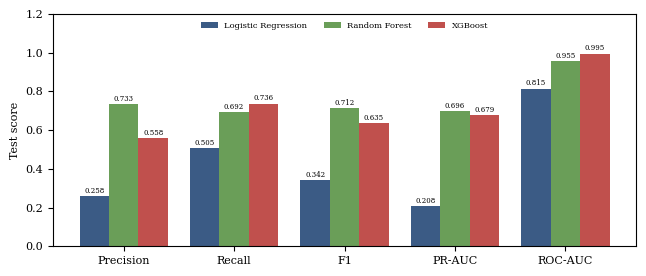

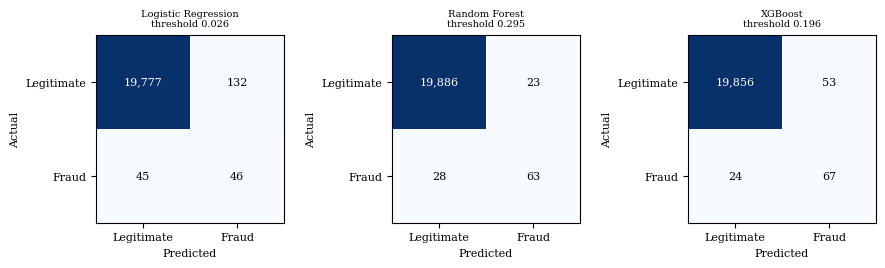

In [31]:
# ---- Three-model comparison: Logistic Regression vs Random Forest vs XGBoost ----
MODELS3 = [m for m in ["Logistic Regression", "Random Forest", "XGBoost"] if m in fitted]
log(f"Models compared: {MODELS3}")

# 1) One table with the test results (Table V) and the CV / validation results (Table IV)
cols = ["precision", "recall", "f1", "pr_auc", "roc_auc", "accuracy", "TP", "FP", "FN", "TN", "threshold"]
three = (table_V.set_index("model").loc[MODELS3, cols]
         .join(table_IV.set_index("model")[["cv_pr_auc_mean", "cv_pr_auc_sd", "val_pr_auc"]]))
three.to_csv(f"{OUT}/three_model_comparison.csv")
print("=== TEST RESULTS FOR THE THREE MODELS (threshold = validation F1-optimal) ===")
display(three.round(4))

for m in MODELS3:
    r = three.loc[m]
    print(f"{m:<20} Precision {r.precision:.4f} | Recall {r.recall:.4f} | F1 {r.f1:.4f} | "
          f"PR-AUC {r.pr_auc:.4f} | ROC-AUC {r.roc_auc:.4f} | Accuracy {r.accuracy:.4f}")
best3 = three["pr_auc"].astype(float).idxmax()
print(f"\nHighest test PR-AUC: {best3}  (the model selected on validation is {SEL})")

# 2) Grouped bar chart of the main metrics
mets, labels = ["precision", "recall", "f1", "pr_auc", "roc_auc"], ["Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]
colors = {"Logistic Regression": "#3B5B85", "Random Forest": "#6A9E58", "XGBoost": "#C0504D"}
x, w = np.arange(len(mets)), 0.8 / len(MODELS3)
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for k, m in enumerate(MODELS3):
    bars = ax.bar(x + (k - (len(MODELS3) - 1) / 2) * w, three.loc[m, mets].astype(float).values, w,
                  label=m, color=colors[m])
    ax.bar_label(bars, fmt="%.3f", fontsize=5, padding=1)
ax.set_xticks(x, labels); ax.set_ylim(0, 1.2); ax.set_ylabel("Test score")
ax.legend(frameon=False, fontsize=6, ncol=len(MODELS3), loc="upper center")
plt.tight_layout(); plt.savefig(f"{FIG}/three_model_metrics.png", dpi=300); plt.show()

# 3) Confusion matrix for each model, side by side
fig, axs = plt.subplots(1, len(MODELS3), figsize=(3 * len(MODELS3), 2.7))
for ax, m in zip(np.atleast_1d(axs), MODELS3):
    cm = confusion_matrix(Yt, (SCORES[m] >= THR[m]).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Legitimate", "Fraud"]); ax.set_yticks([0, 1], ["Legitimate", "Fraud"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{m}\nthreshold {THR[m]:.3f}", fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/three_model_confusion_matrices.png", dpi=300); plt.show()


## Step 16 — Download everything

In [33]:
import os
targets = [d for d in ["results", "artifacts"] if os.path.isdir(d) and len(os.listdir(d)) > 0]
if targets:
    targets_str = " ".join(targets)
    get_ipython().system(f"zip -qr fraud_results.zip {targets_str}")
    from google.colab import files
    files.download("fraud_results.zip")
else:
    print("Error: Neither 'results' nor 'artifacts' directories exist or contain files to zip. Please run preceding steps first.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>